# Proyecto final: Agente Inversor
## Fase 1. Análisis exploratorio de datos (EDA)

**Activo financiero:** Bitcoin frente al dólar estadounidense (BTC/USD)

**Fuente de datos:** Repositorio público de Gym Trading Env.

**Asignatura:** Simulación y Aprendizaje por Refuerzo MIA 2026-5

**Equipo:** Grupo de trabajo 4 — Agente Inversor

---

## Introducción

La toma de decisiones de inversión constituye un problema secuencial en el que es necesario decidir cuánto capital exponer a un activo, considerando la evolución de los precios, la incertidumbre del mercado y los costos asociados a las operaciones. En este contexto, el aprendizaje por refuerzo (*Reinforcement Learning*, RL) permite formular un agente que interactúa con un entorno, selecciona acciones y aprende a partir de las recompensas obtenidas.

El presente proyecto busca desarrollar un agente de aprendizaje por refuerzo capaz de decidir qué proporción del capital invertir en Bitcoin, utilizando información histórica del precio BTC/USD. El agente podrá seleccionar entre tres niveles de exposición: 0 %, 50 % y 100 % del capital disponible.

Antes de construir el entorno de simulación y entrenar el agente, es necesario realizar un análisis exploratorio de los datos. Esta etapa permite comprender las características del activo, identificar posibles problemas de calidad y estudiar patrones en los precios, los retornos y la volatilidad que puedan orientar la formulación del problema.

Los resultados del análisis también servirán para seleccionar las variables de observación del agente, establecer una separación temporal entre los datos de entrenamiento y evaluación y reducir el riesgo de utilizar información futura durante la toma de decisiones.

## Objetivos

### Objetivo general

Analizar y preparar los datos históricos de BTC/USD para fundamentar el diseño de un entorno de inversión basado en aprendizaje por refuerzo.

### Objetivos específicos

- Examinar la estructura, cobertura temporal, tipos de datos y calidad de la base.
- Analizar la evolución histórica del precio y la distribución de los retornos.
- Identificar períodos de mayor y menor volatilidad y posibles tendencias o caídas relevantes.
- Construir indicadores técnicos que puedan representar el estado observado por el agente.
- Definir una separación cronológica entre entrenamiento, validación y prueba sin usar información futura.

> Este notebook reúne el análisis exploratorio del proyecto y prepara los datos que usa el código de `src/`. Se ejecuta desde la carpeta del repositorio, sin depender de Colab.

### 1. Conectar y guardar la base

In [1]:
# ============================================================
# 1. CONFIGURACIÓN Y CARGA DE DATOS
# Proyecto: Agente Inversor
# Fase: Análisis exploratorio de BTC/USD
# ============================================================

import hashlib
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Raíz del repositorio (el notebook vive en notebooks/)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

# Semilla de reproducibilidad para los análisis que la requieran
SEMILLA = 42
np.random.seed(SEMILLA)

# Fuente pública del dataset (copia incluida en data/)
URL_DATA = (
    "https://raw.githubusercontent.com/ClementPerroud/"
    "Gym-Trading-Env/main/examples/data/BTC_USD-Hourly.csv"
)
RUTA_CSV = RAIZ / "data" / "BTC_USD-Hourly.csv"
SHA256_ESPERADO = "b5ccfdef2aa852ded1ea03378c1777757d2c27a81d53e0fc81af0011fed9cccf"

if not RUTA_CSV.exists():
    pd.read_csv(URL_DATA).to_csv(RUTA_CSV, index=False)
assert hashlib.sha256(RUTA_CSV.read_bytes()).hexdigest() == SHA256_ESPERADO, "El CSV no es el del proyecto"

df = pd.read_csv(RUTA_CSV)
print(f"Ruta del archivo: {RUTA_CSV.relative_to(RAIZ)}")
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")

display(df.head())

Ruta del archivo: data/BTC_USD-Hourly.csv
Filas: 33,259
Columnas: 9


,unix,date,symbol,open,high,low,close,volume,Volume USD
0,1646092800,2022-03-01 00:00:00,BTC/USD,43221.71,43626.49,43185.48,43312.27,52.056320,2.254677e+06
1,1646089200,2022-02-28 23:00:00,BTC/USD,43085.30,43364.81,42892.37,43178.98,106.816103,4.612210e+06
2,1646085600,2022-02-28 22:00:00,BTC/USD,41657.23,44256.08,41650.29,42907.32,527.540571,2.263535e+07
3,1646082000,2022-02-28 21:00:00,BTC/USD,41917.09,41917.09,41542.60,41659.53,69.751680,2.905822e+06
4,1646078400,2022-02-28 20:00:00,BTC/USD,41361.99,41971.00,41284.11,41914.97,247.151654,1.035935e+07


### Resultados de la carga de datos

La base de datos se cargó desde la copia del repositorio (`data/BTC_USD-Hourly.csv`), que es el mismo archivo público de Gym Trading Env; la huella SHA-256 confirma que no cambió.

El conjunto de datos contiene **33.259 registros y 9 columnas**, correspondientes a información histórica del mercado BTC/USD. Entre las variables disponibles se encuentran la fecha (`date`), el símbolo del activo (`symbol`), los precios de apertura (`open`), máximo (`high`), mínimo (`low`) y cierre (`close`), así como el volumen negociado y su valor expresado en dólares.

La estructura de la base permite estudiar la evolución del precio de Bitcoin, calcular retornos y construir indicadores técnicos para la posterior formulación del agente de aprendizaje por refuerzo.

### 2. Inspección de la estructura

In [2]:
# ============================================================
# 2. INSPECCIÓN INICIAL DE LA BASE
# ============================================================

print("Columnas disponibles:")
print(df.columns.tolist())

print("\nInformación general:")
df.info()

print("\nTipos de datos:")
display(df.dtypes.to_frame(name="Tipo de dato"))

print("\nValores faltantes:")
display(
    df.isnull()
      .sum()
      .to_frame(name="Cantidad de faltantes")
)

print("\nEstadísticas descriptivas:")
display(df.describe(include="all").T)

Columnas disponibles:
['unix', 'date', 'symbol', 'open', 'high', 'low', 'close', 'volume', 'Volume USD']

Información general:
<class 'pandas.DataFrame'>
RangeIndex: 33259 entries, 0 to 33258
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   unix        33259 non-null  int64  
 1   date        33259 non-null  str    
 2   symbol      33259 non-null  str    
 3   open        33259 non-null  float64
 4   high        33259 non-null  float64
 5   low         33259 non-null  float64
 6   close       33259 non-null  float64
 7   volume      33259 non-null  float64
 8   Volume USD  33259 non-null  float64
dtypes: float64(6), int64(1), str(2)
memory usage: 2.3 MB

Tipos de datos:


,Tipo de dato
unix,int64
date,str
symbol,str
open,float64
high,float64
low,float64
close,float64
volume,float64
Volume USD,float64



Valores faltantes:


,Cantidad de faltantes
unix,0
date,0
symbol,0
open,0
high,0
low,0
close,0
volume,0
Volume USD,0



Estadísticas descriptivas:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
unix,33259.0,NaN,NaN,NaN,1586228400.0,34564286.296696,1526364000.0,1556296200.0,1586228400.0,1616160600.0,1646092800.0
date,33259,33259,2022-03-01 00:00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
symbol,33259,1,BTC/USD,33259,NaN,NaN,NaN,NaN,NaN,NaN,NaN
open,33259.0,NaN,NaN,NaN,20119.546772,18537.219607,3139.76,7022.865,9700.04,36415.305,68635.05
high,33259.0,NaN,NaN,NaN,20232.957473,18646.950933,3158.34,7055.835,9740.27,36735.38,69000.0
low,33259.0,NaN,NaN,NaN,19997.069777,18418.320297,3122.28,6970.57,9657.0,36104.235,68447.0
close,33259.0,NaN,NaN,NaN,20120.6848,18537.695044,3139.76,7022.865,9700.32,36423.04,68627.01
volume,33259.0,NaN,NaN,NaN,1612380.146335,3102327.676408,0.0,190.324133,609327.06,1929239.915,68570613.16
Volume USD,33259.0,NaN,NaN,NaN,2965701.403312,7329786.903391,0.0,168.28,524.83,3120014.4439,258232381.746773


### Análisis de la estructura y calidad de los datos

La inspección inicial permitió identificar nueve variables y revisar sus tipos de datos. La columna `date` se encuentra inicialmente en formato de texto, mientras que las variables de precios y volumen están representadas mediante tipos numéricos. La columna `symbol` identifica el activo financiero analizado y la columna `unix` guarda la misma fecha como marca de tiempo en segundos.

Ninguna columna tiene valores faltantes. Los `NaN` que aparecen en la tabla de estadísticas descriptivas no son datos perdidos: corresponden a las filas `unique`, `top` y `freq`, que solo aplican a columnas de texto, y a las filas numéricas (`mean`, `std`, etc.), que no aplican a `date` ni a `symbol`.

Hay dos columnas de volumen: `volume` y `Volume USD`. Su relación se revisa en la sección 15.

### 3. Validación temporal

In [3]:
# ============================================================
# 3. VALIDACIÓN DE FECHAS Y ORDEN CRONOLÓGICO
# ============================================================

posibles_fechas = ["date", "datetime", "timestamp", "time"]
col_fecha = next(
    (col for col in df.columns
     if col.lower() in posibles_fechas),
    None
)

if col_fecha is None:
    raise ValueError(
        "No se identificó la columna temporal. "
        "Revisa df.columns.tolist() y ajusta col_fecha."
    )

df[col_fecha] = pd.to_datetime(
    df[col_fecha],
    errors="coerce",
    utc=True
)

fechas_invalidas = df[col_fecha].isna().sum()

print("Fechas inválidas:", fechas_invalidas)

df = df.dropna(subset=[col_fecha]).copy()
df = df.sort_values(col_fecha).reset_index(drop=True)

print("Primera observación:", df[col_fecha].min())
print("Última observación:", df[col_fecha].max())
print("Filas duplicadas completas:", df.duplicated().sum())

display(df.head())
display(df.tail())

Fechas inválidas: 0
Primera observación: 2018-05-15 06:00:00+00:00
Última observación: 2022-03-01 00:00:00+00:00
Filas duplicadas completas: 0


,unix,date,symbol,open,high,low,close,volume,Volume USD
0,1526364000,2018-05-15 06:00:00+00:00,BTC/USD,8733.86,8796.68,8707.28,8740.99,4906603.14,559.93
1,1526367600,2018-05-15 07:00:00+00:00,BTC/USD,8740.99,8766.00,8721.11,8739.00,2390398.89,273.58
2,1526371200,2018-05-15 08:00:00+00:00,BTC/USD,8739.00,8750.27,8660.53,8728.49,7986062.84,917.79
3,1526374800,2018-05-15 09:00:00+00:00,BTC/USD,8728.49,8754.40,8701.35,8708.32,1593991.98,182.62
4,1526378400,2018-05-15 10:00:00+00:00,BTC/USD,8708.32,8865.00,8695.11,8795.90,11101273.74,1260.69


,unix,date,symbol,open,high,low,close,volume,Volume USD
33254,1646078400,2022-02-28 20:00:00+00:00,BTC/USD,41361.99,41971.00,41284.11,41914.97,247.151654,1.035935e+07
33255,1646082000,2022-02-28 21:00:00+00:00,BTC/USD,41917.09,41917.09,41542.60,41659.53,69.751680,2.905822e+06
33256,1646085600,2022-02-28 22:00:00+00:00,BTC/USD,41657.23,44256.08,41650.29,42907.32,527.540571,2.263535e+07
33257,1646089200,2022-02-28 23:00:00+00:00,BTC/USD,43085.30,43364.81,42892.37,43178.98,106.816103,4.612210e+06
33258,1646092800,2022-03-01 00:00:00+00:00,BTC/USD,43221.71,43626.49,43185.48,43312.27,52.056320,2.254677e+06


### Validación y ordenamiento temporal

La variable `date` se convirtió al formato de fecha y hora, y los registros se ordenaron cronológicamente para facilitar el análisis de la serie temporal.

### Periodo de análisis

El conjunto de datos contiene 33.259 observaciones horarias del par BTC/USD, comprendidas entre el 15 de mayo de 2018 a las 06:00 UTC y el 1 de marzo de 2022 a las 00:00 UTC. La información incluye variables de mercado como los precios de apertura, máximo, mínimo y cierre, además del volumen de negociación.

Este periodo permite estudiar diferentes condiciones del mercado, incluyendo tendencias alcistas y bajistas, cambios en la volatilidad y movimientos extremos del precio.

El ordenamiento cronológico es fundamental para el proyecto, ya que las decisiones de inversión deben basarse únicamente en información disponible en el momento de actuar. Por esta razón, la división posterior entre entrenamiento y evaluación se realizará respetando el orden temporal, sin mezclar aleatoriamente las observaciones.

Finalmente, se verificó que no existieran registros duplicados en la variable temporal y que los intervalos entre observaciones consecutivas fueran regulares, con una frecuencia de una hora.

## 4. Revisión inicial de precios

In [4]:
# ============================================================
# 4. VALIDACIÓN DE LAS VARIABLES DE PRECIO
# ============================================================

columnas_lower = {col.lower(): col for col in df.columns}

if "close" not in columnas_lower:
    raise ValueError(
        "No se encontró la columna 'close'. "
        "Revisa las columnas disponibles."
    )

col_close = columnas_lower["close"]

df[col_close] = pd.to_numeric(
    df[col_close],
    errors="coerce"
)

print("Valores de cierre faltantes:", df[col_close].isna().sum())
print("Precios de cierre menores o iguales a cero:",
      (df[col_close] <= 0).sum())

display(df[[col_fecha, col_close]].head())
display(df[col_close].describe())

Valores de cierre faltantes: 0
Precios de cierre menores o iguales a cero: 0


,date,close
0,2018-05-15 06:00:00+00:00,8740.99
1,2018-05-15 07:00:00+00:00,8739.00
2,2018-05-15 08:00:00+00:00,8728.49
3,2018-05-15 09:00:00+00:00,8708.32
4,2018-05-15 10:00:00+00:00,8795.90


count    33259.000000
mean     20120.684800
std      18537.695044
min       3139.760000
25%       7022.865000
50%       9700.320000
75%      36423.040000
max      68627.010000
Name: close, dtype: float64

### Revisión preliminar del precio de cierre

La variable `close` corresponde al precio de cierre de Bitcoin frente al dólar estadounidense (BTC/USD) y constituye una variable fundamental para el análisis de la evolución del activo y el cálculo de sus retornos.

La revisión de calidad confirmó que la columna contiene **33.259 observaciones numéricas**, sin valores no numéricos ni precios menores o iguales a cero. Por tanto, los datos de cierre cumplen estos criterios básicos de validez y pueden utilizarse para continuar con el análisis exploratorio.

Las estadísticas descriptivas muestran un precio promedio de **20.120,68 USD**, una mediana de **9.700,32 USD** y una desviación estándar de **18.537,70 USD**. El precio mínimo registrado es de **3.139,76 USD**, mientras que el máximo alcanza **68.627,01 USD**.

La diferencia entre la media y la mediana, junto con la amplitud de los precios observados, evidencia una variación considerable del valor del activo durante el período analizado. Estos resultados justifican profundizar en la evolución temporal del precio, la distribución de los retornos y los períodos de volatilidad.

Es importante señalar que estas estadísticas describen el comportamiento histórico de los precios, pero no permiten concluir por sí solas que exista una estrategia de inversión rentable. Para ello será necesario evaluar el agente y compararlo con estrategias de referencia en datos que no hayan sido utilizados durante el entrenamiento.

## 5. Evolución histórica del precio BTC/USD

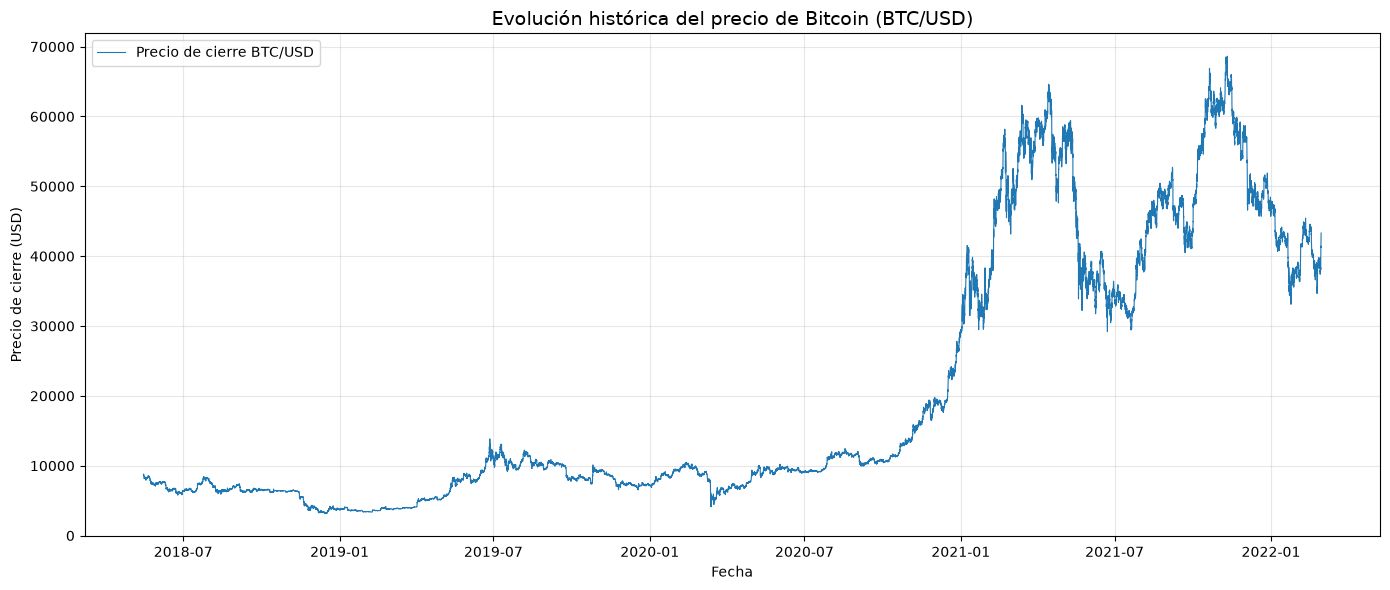

In [5]:
# ============================================================
# 5. EVOLUCIÓN HISTÓRICA DEL PRECIO BTC/USD
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    df[col_fecha],
    df["close"],
    linewidth=0.8,
    label="Precio de cierre BTC/USD"
)

plt.title(
    "Evolución histórica del precio de Bitcoin (BTC/USD)",
    fontsize=14
)
plt.xlabel("Fecha")
plt.ylabel("Precio de cierre (USD)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 5.1. Análisis de la evolución histórica del precio

La gráfica presenta la evolución del precio de cierre de Bitcoin frente al dólar estadounidense (BTC/USD) entre mayo de 2018 y marzo de 2022. Se observa un comportamiento variable, con períodos de relativa estabilidad, tendencias alcistas y episodios de caídas pronunciadas.

Durante 2018 y 2019, el precio se mantuvo en niveles considerablemente inferiores a los observados posteriormente, con fluctuaciones y períodos de recuperación. En 2020 se aprecia una recuperación progresiva, aunque también se presenta una caída pronunciada durante el primer semestre del año.

A partir de finales de 2020 se evidencia un incremento significativo del precio, que continúa durante 2021 y alcanza sus niveles máximos hacia finales de ese año. Posteriormente, el activo presenta una corrección importante y una mayor variabilidad de los precios hasta el final del período observado.

Este comportamiento muestra que la serie no evoluciona de manera uniforme: existen diferentes condiciones de mercado, con variaciones en la tendencia y en la magnitud de los movimientos. Por ello, utilizar únicamente el precio de cierre podría resultar insuficiente para representar las condiciones del mercado que enfrenta el agente.

En consecuencia, se considera pertinente analizar los retornos y la volatilidad, e incorporar indicadores técnicos que permitan describir los movimientos recientes del precio. Estas variables podrán utilizarse para construir el estado del agente de Reinforcement Learning.

Finalmente, la gráfica representa exclusivamente el comportamiento histórico del activo y no demuestra por sí sola que sea posible anticipar sus movimientos futuros ni obtener rentabilidades positivas de manera consistente.

### 6. Cálculo y análisis de retornos

In [6]:
# ============================================================
# 6. CÁLCULO Y ANÁLISIS DE RETORNOS
# ============================================================

# Retorno porcentual entre observaciones consecutivas
df["return"] = df["close"].pct_change()

# Retorno logarítmico
df["log_return"] = np.log(
    df["close"] / df["close"].shift(1)
)

print("Estadísticas descriptivas de los retornos:")
display(df[["return", "log_return"]].describe())

print("\nValores faltantes en los retornos:")
display(df[["return", "log_return"]].isna().sum())

Estadísticas descriptivas de los retornos:


,return,log_return
count,33258.000000,33258.000000
mean,0.000081,0.000048
std,0.008159,0.008159
min,-0.165484,-0.180903
25%,-0.002704,-0.002707
50%,0.000079,0.000079
75%,0.002911,0.002906
max,0.228118,0.205483



Valores faltantes en los retornos:


return        1
log_return    1
dtype: int64

### 6.1. Análisis descriptivo de los retornos

Los retornos se calcularon a partir de la variación porcentual del precio de cierre entre observaciones consecutivas. También se calcularon los retornos logarítmicos como una medida alternativa para caracterizar los cambios relativos del precio.

Se obtuvieron 33.258 observaciones válidas para ambas variables. El retorno porcentual promedio es de aproximadamente 0,0081 % por observación, mientras que la mediana es cercana a 0,0079 %. Estos valores indican que el retorno promedio y el retorno mediano del período analizado fueron ligeramente positivos, aunque esto no implica que todas las observaciones hayan presentado ganancias.

La desviación estándar de los retornos porcentuales es de aproximadamente 0,8159 puntos porcentuales, lo que refleja una variabilidad considerable en los cambios horarios del precio. Asimismo, los retornos presentan valores extremos: el mínimo observado es de aproximadamente −16,55 % y el máximo de 22,81 %.

La diferencia entre los valores extremos y los percentiles centrales evidencia que, aunque muchas variaciones se concentran cerca de cero, también existen movimientos pronunciados que pueden afectar significativamente el valor de una inversión.

Estos resultados justifican incorporar medidas de volatilidad en el estado del agente y considerar el riesgo al evaluar las estrategias de inversión. También muestran por qué el retorno acumulado no debe ser la única medida utilizada para determinar el desempeño del agente.

Se observa un valor faltante en ambas series de retornos, correspondiente a la primera observación, debido a que no existe un precio anterior con el cual calcular la variación. Este comportamiento es esperado al utilizar la función `pct_change()` y los retornos logarítmicos.

### 7. Visualización de los retornos

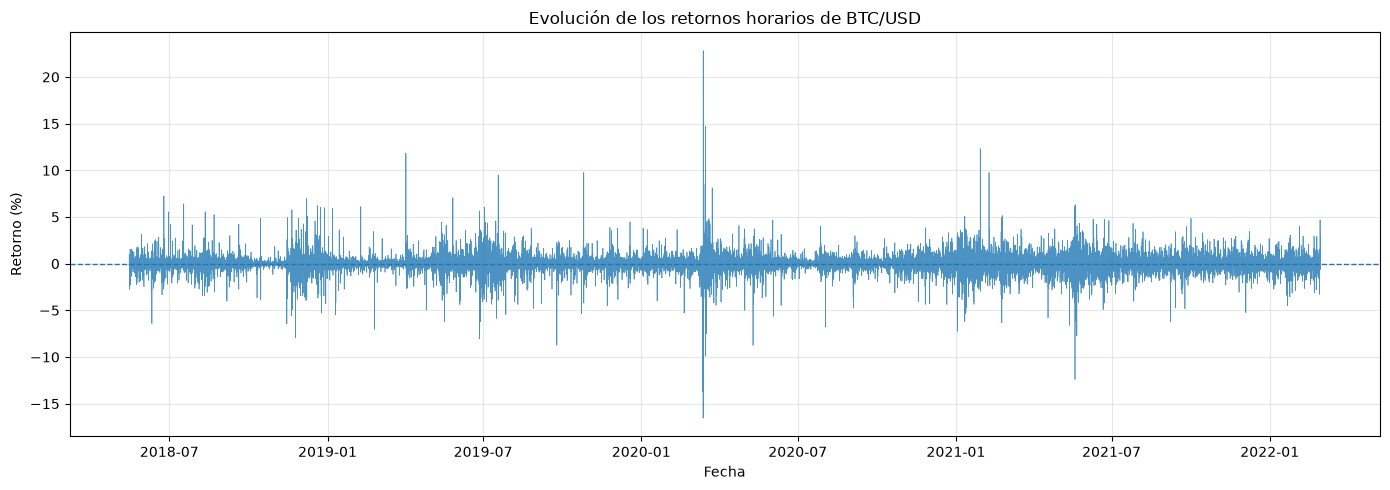

In [7]:
# ============================================================
# 7. VISUALIZACIÓN DE LOS RETORNOS
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    df[col_fecha],
    df["return"] * 100,
    linewidth=0.5,
    alpha=0.8
)

plt.axhline(0, linewidth=1, linestyle="--")

plt.title("Evolución de los retornos horarios de BTC/USD")
plt.xlabel("Fecha")
plt.ylabel("Retorno (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.1. Comportamiento temporal de los retornos

El gráfico muestra la evolución de los retornos horarios de BTC/USD durante el período analizado. La mayoría de las variaciones se concentra alrededor de cero, alternando movimientos positivos y negativos. Sin embargo, también se observan episodios con fluctuaciones de mayor magnitud.

Destaca la presencia de movimientos extremos durante algunos períodos, particularmente alrededor de marzo de 2020, cuando se presentan variaciones positivas y negativas pronunciadas. También se identifican intervalos con una mayor concentración de fluctuaciones, lo que sugiere que la variabilidad de los retornos no permanece constante a lo largo del tiempo.

Este comportamiento es compatible con la presencia de agrupamientos de volatilidad, en los que períodos relativamente tranquilos alternan con períodos de mayor incertidumbre. No obstante, esta observación visual deberá complementarse con medidas cuantitativas.

Desde la perspectiva del aprendizaje por refuerzo, estos resultados son relevantes porque una misma exposición al activo puede producir resultados muy diferentes según las condiciones del mercado. Por ello, se analizará la volatilidad mediante ventanas móviles y se evaluará una función de recompensa alternativa que considere el riesgo, además del retorno neto de los costos de transacción.

### 7.2. Distribución de los retornos horarios

El histograma compara los retornos horarios con una curva normal de la misma media y desviación.

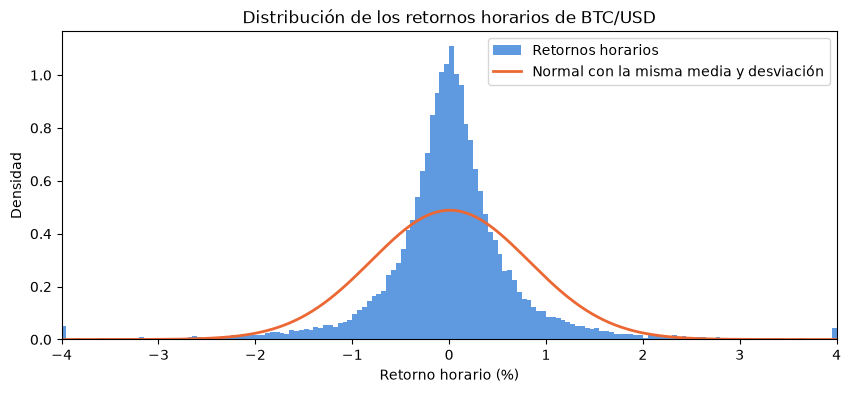

Curtosis (exceso): 49.0
Horas con |retorno| > 3 desviaciones: 1.77 % (una normal daría 0,27 %)


In [8]:
r = df["return"].dropna() * 100
x = np.linspace(-4, 4, 400)
normal = np.exp(-0.5 * ((x - r.mean()) / r.std()) ** 2) / (r.std() * np.sqrt(2 * np.pi))

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(r.clip(-4, 4), bins=160, density=True, color="#2a78d6", alpha=0.75, label="Retornos horarios")
ax.plot(x, normal, color="#eb6834", lw=2, label="Normal con la misma media y desviación")
ax.set_xlim(-4, 4)
ax.set_xlabel("Retorno horario (%)")
ax.set_ylabel("Densidad")
ax.set_title("Distribución de los retornos horarios de BTC/USD")
ax.legend()
plt.show()

print(f"Curtosis (exceso): {r.kurt():.1f}")
print(f"Horas con |retorno| > 3 desviaciones: {(abs(r - r.mean()) > 3 * r.std()).mean() * 100:.2f} % "
      f"(una normal daría 0,27 %)")

La distribución tiene un pico más alto en cero y colas más gruesas que la normal: la mayoría de las horas el precio casi no se mueve, pero los movimientos extremos son mucho más frecuentes de lo que predice una normal. Para el agente esto significa que unas pocas horas pueden explicar gran parte de la ganancia o de la pérdida, y que el costo de estar invertido en el momento equivocado puede ser muy alto.

### 8. Análisis de volatilidad móvil

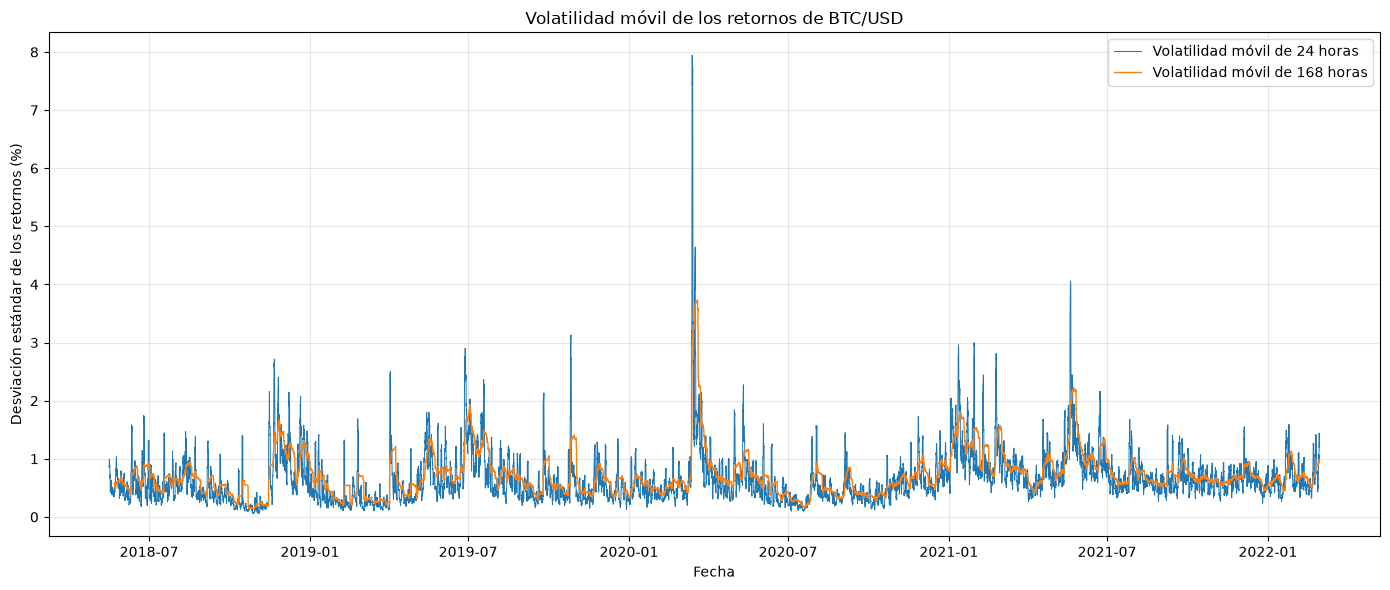

In [9]:
# ============================================================
# 8. ANÁLISIS DE VOLATILIDAD MÓVIL
# ============================================================

# Desviación estándar de los retornos horarios
df["volatility_24h"] = df["return"].rolling(
    window=24,
    min_periods=24
).std()

df["volatility_168h"] = df["return"].rolling(
    window=168,
    min_periods=168
).std()

plt.figure(figsize=(14, 6))

plt.plot(
    df[col_fecha],
    df["volatility_24h"] * 100,
    linewidth=0.7,
    label="Volatilidad móvil de 24 horas"
)

plt.plot(
    df[col_fecha],
    df["volatility_168h"] * 100,
    linewidth=1.0,
    label="Volatilidad móvil de 168 horas"
)

plt.title("Volatilidad móvil de los retornos de BTC/USD")
plt.xlabel("Fecha")
plt.ylabel("Desviación estándar de los retornos (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# Estadísticas descriptivas de la volatilidad
display(
    df[["volatility_24h", "volatility_168h"]]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
volatility_24h,33235.0,0.006702,0.004669,0.000570,0.003819,0.005702,0.008148,0.079441
volatility_168h,33091.0,0.007216,0.003806,0.001392,0.005070,0.006534,0.008401,0.037278


### 8.1. Análisis descriptivo de la volatilidad

Para estudiar la variabilidad de los retornos de BTC/USD se calcularon dos medidas de volatilidad móvil: una ventana de 24 observaciones, que representa aproximadamente un día, y una ventana de 168 observaciones, equivalente a una semana, considerando la frecuencia horaria de los datos.

La volatilidad móvil de 24 horas presenta una media de 0,006702 y una desviación estándar de 0,004669. Por su parte, la volatilidad móvil de 168 horas tiene una media de 0,007216 y una desviación estándar de 0,003806. Estos valores están expresados en unidades decimales, por lo que corresponden aproximadamente a 0,6702 % y 0,7216 %, respectivamente.

La volatilidad de 24 horas alcanza un máximo de 0,079441, equivalente a aproximadamente 7,94 %, mientras que la volatilidad semanal alcanza un máximo de 0,037278, equivalente a 3,73 %. La diferencia entre ambos máximos indica que la ventana más corta responde con mayor intensidad a episodios puntuales de movimientos extremos.

Asimismo, la volatilidad semanal presenta una evolución más suavizada, ya que incorpora un período más amplio de retornos. Esta característica permite distinguir entre fluctuaciones de corto plazo y condiciones de mercado que persisten durante varios días.

En conjunto, los resultados muestran que la variabilidad de los retornos no es constante. Por ello, la volatilidad móvil puede aportar información relevante para representar el estado del mercado y estudiar el comportamiento del agente ante diferentes niveles de incertidumbre.

### 8.2. Comportamiento temporal de la volatilidad

La gráfica muestra que la volatilidad de BTC/USD varía considerablemente durante el período estudiado. La serie de 24 horas presenta fluctuaciones más abruptas, mientras que la serie de 168 horas evoluciona de manera más gradual debido a que considera una ventana de observación más amplia.

Se identifican episodios destacados de volatilidad alrededor de finales de 2018 y comienzos de 2019, a mediados de 2019, durante marzo de 2020 y en distintos momentos de 2021. El pico más pronunciado de la serie de corto plazo aparece alrededor de marzo de 2020, lo que coincide con un período de movimientos extremos observado previamente en el gráfico de retornos.

También se observan períodos en los que ambas medidas disminuyen y se mantienen en niveles relativamente bajos. La alternancia entre intervalos tranquilos y episodios de alta variabilidad evidencia que las condiciones del mercado cambian a lo largo del tiempo.

Este comportamiento es relevante para el proyecto porque una estrategia con una exposición elevada puede experimentar resultados diferentes según el nivel de volatilidad presente. En consecuencia, se considerará la volatilidad reciente como una variable candidata para el estado del agente de Reinforcement Learning.

Sin embargo, incorporar esta variable no garantiza que el agente gestione adecuadamente el riesgo. Su utilidad deberá evaluarse mediante experimentos y comparaciones en datos no utilizados durante el entrenamiento.

### 8.3. Tendencias y periodos de caída

Para ubicar las caídas importantes se calcula el *drawdown* del precio: la caída desde el máximo alcanzado hasta ese momento.

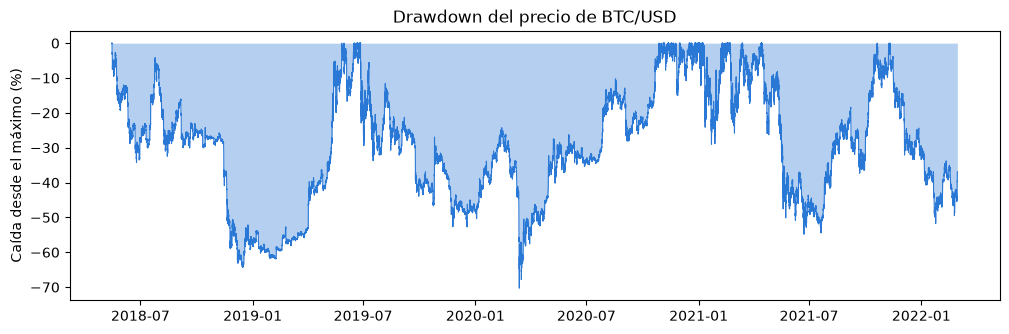

,first,last,variacion_pct
date,,,
2018,8740.99,3693.30,-57.75
2019,3693.83,7168.36,94.06
2020,7150.00,28992.79,305.49
2021,29056.94,46214.37,59.05
2022,46650.66,43312.27,-7.16


Peor caída desde un máximo: -70.29 % (2020-03-13 01:00:00+00:00)


In [11]:
dd_precio = (df["close"] / df["close"].cummax() - 1) * 100
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.fill_between(df[col_fecha], dd_precio, 0, color="#2a78d6", alpha=0.35, lw=0)
ax.plot(df[col_fecha], dd_precio, color="#2a78d6", lw=0.8)
ax.set_ylabel("Caída desde el máximo (%)")
ax.set_title("Drawdown del precio de BTC/USD")
plt.show()

anual = df.groupby(df[col_fecha].dt.year)["close"].agg(["first", "last"])
anual["variacion_pct"] = (anual["last"] / anual["first"] - 1) * 100
display(anual.round(2))
print(f"Peor caída desde un máximo: {dd_precio.min():.2f} % "
      f"({df.loc[dd_precio.idxmin(), col_fecha]})")

La serie alterna tendencias muy distintas: una caída larga en 2018, una recuperación en 2019, el desplome de marzo de 2020, una subida fuerte desde finales de 2020 y una nueva corrección a finales de 2021. Que el comportamiento del mercado cambie tanto entre periodos es importante para el proyecto: lo que el agente aprenda en una etapa puede no servir en la siguiente.

### 9. Construcción de indicadores técnicos

In [12]:
# ============================================================
# 9. CONSTRUCCIÓN DE INDICADORES TÉCNICOS
# ============================================================

# Retorno acumulado de las últimas 24 horas
df["return_24h"] = df["close"].pct_change(24)

# Media móvil del precio de cierre de las últimas 24 horas
df["sma_24h"] = df["close"].rolling(
    window=24,
    min_periods=24
).mean()

# Diferencia relativa entre el precio y su media móvil
df["price_vs_sma_24h"] = (
    df["close"] / df["sma_24h"]
) - 1

# Volatilidad móvil de los retornos de 24 horas
# Ya fue calculada en la sección anterior como volatility_24h

columnas_indicadores = [
    "return_24h",
    "price_vs_sma_24h",
    "volatility_24h"
]

print("Estadísticas de los indicadores:")
display(df[columnas_indicadores].describe().T)

print("\nValores faltantes por indicador:")
display(df[columnas_indicadores].isna().sum())

Estadísticas de los indicadores:


,count,mean,std,min,25%,50%,75%,max
return_24h,33235.0,0.001862,0.038611,-0.46720,-0.014879,0.001269,0.018779,0.356513
price_vs_sma_24h,33236.0,0.000655,0.021426,-0.35019,-0.007536,0.000628,0.009377,0.250508
volatility_24h,33235.0,0.006702,0.004669,0.00057,0.003819,0.005702,0.008148,0.079441



Valores faltantes por indicador:


return_24h          24
price_vs_sma_24h    23
volatility_24h      24
dtype: int64

### 10. Visualización de indicadores

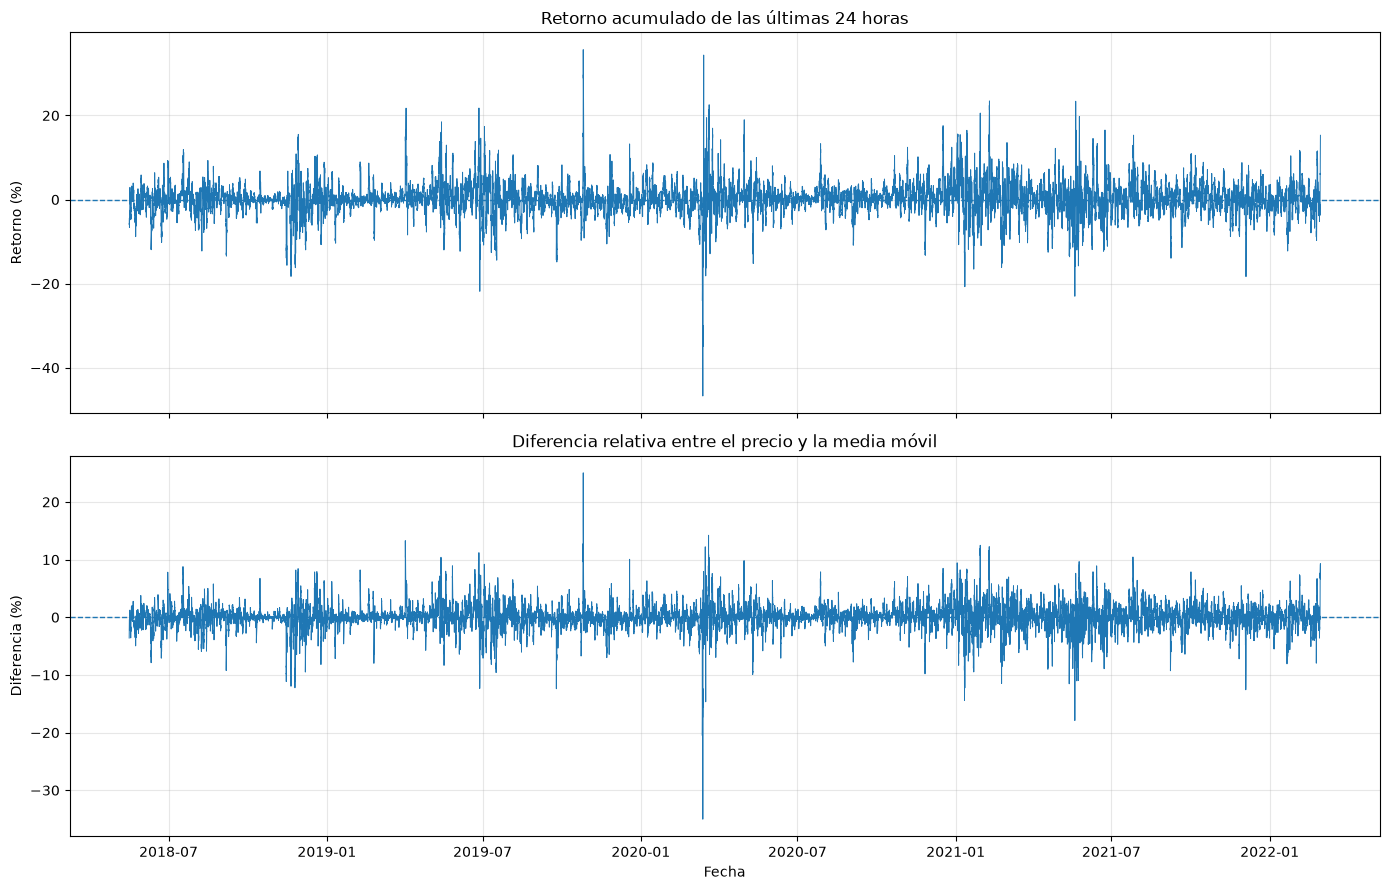

In [13]:
# ============================================================
# 10. VISUALIZACIÓN DE INDICADORES
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].plot(
    df[col_fecha],
    df["return_24h"] * 100,
    linewidth=0.7
)
axes[0].axhline(0, linestyle="--", linewidth=1)
axes[0].set_title("Retorno acumulado de las últimas 24 horas")
axes[0].set_ylabel("Retorno (%)")
axes[0].grid(alpha=0.3)

axes[1].plot(
    df[col_fecha],
    df["price_vs_sma_24h"] * 100,
    linewidth=0.7
)
axes[1].axhline(0, linestyle="--", linewidth=1)
axes[1].set_title("Diferencia relativa entre el precio y la media móvil")
axes[1].set_ylabel("Diferencia (%)")
axes[1].set_xlabel("Fecha")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 10.1. Análisis de los indicadores técnicos

Se analizaron dos indicadores derivados del precio de cierre de BTC/USD: el retorno acumulado de las últimas 24 horas y la diferencia relativa entre el precio actual y su media móvil de 24 observaciones. También se incorporó la volatilidad móvil de 24 horas, calculada previamente.

El retorno de las últimas 24 horas presenta fluctuaciones alrededor de cero, con movimientos positivos y negativos de diferente magnitud. Se observan episodios en los que las variaciones son considerablemente más pronunciadas, lo que refleja que el comportamiento del activo cambia a lo largo del período analizado.

Por su parte, la diferencia relativa entre el precio y su media móvil permite observar si el precio se encuentra por encima o por debajo de su nivel promedio reciente. Los valores positivos indican que el precio está por encima de la media móvil, mientras que los negativos indican que está por debajo. Las desviaciones más pronunciadas reflejan diferencias importantes respecto al comportamiento reciente del precio.

Ambos indicadores presentan movimientos extremos en determinados momentos, lo que resulta coherente con la variabilidad identificada en los retornos y la volatilidad. Sin embargo, estos indicadores son descriptivos y no deben interpretarse como señales que garanticen futuras subidas o bajadas del precio.

En conjunto, los resultados respaldan la selección preliminar de variables que representen el rendimiento reciente, la tendencia de corto plazo y la volatilidad. Estas variables podrán proporcionar información complementaria para describir las condiciones del mercado al formular el estado del agente de aprendizaje por refuerzo.

### 10.2. Estadísticas descriptivas de los indicadores

El retorno acumulado de las últimas 24 horas presenta una media de 0,001862 en unidades decimales, equivalente aproximadamente a 0,1862 %, y una desviación estándar de 0,038611, equivalente a 3,8611 %. Sus valores oscilan entre −46,72 % y 35,65 %, lo que evidencia la presencia de variaciones importantes en algunos intervalos.

La diferencia relativa entre el precio y la media móvil presenta una media de 0,000655, equivalente a 0,0655 %, y una desviación estándar de 0,021426, equivalente a 2,1426 %. Su rango se encuentra entre −35,02 % y 25,05 %, mostrando que el precio puede alejarse considerablemente de su promedio reciente.

Por su parte, la volatilidad móvil de 24 horas presenta una media de 0,006702, equivalente a 0,6702 %, y un máximo de 0,079441, equivalente a 7,9441 %.

Estas medidas permiten caracterizar diferentes aspectos del mercado: el retorno representa el cambio del precio durante un intervalo, la diferencia respecto a la media móvil describe su posición relativa y la volatilidad mide la dispersión reciente de los retornos horarios.

Los valores extremos justifican revisar la calidad de los registros y verificar que los indicadores estén correctamente calculados. En particular, las variaciones acumuladas de 24 horas no deben confundirse con retornos de una sola hora, ya que corresponden a períodos diferentes.

#### 11. Validación de calidad de los indicadores

In [14]:
# ============================================================
# 11. VALIDACIÓN DE CALIDAD DE LOS INDICADORES
# ============================================================

indicadores = [
    "return_24h",
    "price_vs_sma_24h",
    "volatility_24h"
]

print("Valores faltantes por indicador:")
display(df[indicadores].isna().sum())

print("\nPrimeras observaciones con indicadores faltantes:")
display(
    df.loc[
        df[indicadores].isna().any(axis=1),
        [col_fecha, "close"] + indicadores
    ].head(35)
)

print("\nIntervalos temporales entre observaciones:")
print(df[col_fecha].diff().value_counts().head(10))

print("\nRegistros duplicados por fecha:")
print(df[col_fecha].duplicated().sum())

print("\nRetornos de 24 horas más extremos:")
display(
    df.loc[
        df["return_24h"].abs().nlargest(10).index,
        [col_fecha, "close", "return_24h"]
    ].sort_values("return_24h")
)

Valores faltantes por indicador:


return_24h          24
price_vs_sma_24h    23
volatility_24h      24
dtype: int64


Primeras observaciones con indicadores faltantes:


,date,close,return_24h,price_vs_sma_24h,volatility_24h
0,2018-05-15 06:00:00+00:00,8740.99,NaN,NaN,NaN
1,2018-05-15 07:00:00+00:00,8739.00,NaN,NaN,NaN
2,2018-05-15 08:00:00+00:00,8728.49,NaN,NaN,NaN
3,2018-05-15 09:00:00+00:00,8708.32,NaN,NaN,NaN
4,2018-05-15 10:00:00+00:00,8795.90,NaN,NaN,NaN
5,2018-05-15 11:00:00+00:00,8760.00,NaN,NaN,NaN
6,2018-05-15 12:00:00+00:00,8760.00,NaN,NaN,NaN
7,2018-05-15 13:00:00+00:00,8759.23,NaN,NaN,NaN
8,2018-05-15 14:00:00+00:00,8517.77,NaN,NaN,NaN
9,2018-05-15 15:00:00+00:00,8520.30,NaN,NaN,NaN



Intervalos temporales entre observaciones:
date
0 days 01:00:00    33258
Name: count, dtype: int64

Registros duplicados por fecha:
0

Retornos de 24 horas más extremos:


,date,close,return_24h
16027,2020-03-13 01:00:00+00:00,4111.78,-0.467200
16026,2020-03-13 00:00:00+00:00,4671.37,-0.410631
16025,2020-03-12 23:00:00+00:00,4841.67,-0.389801
16030,2020-03-13 04:00:00+00:00,4865.87,-0.361074
16031,2020-03-13 05:00:00+00:00,4980.05,-0.349107
16028,2020-03-13 02:00:00+00:00,5049.75,-0.338934
16032,2020-03-13 06:00:00+00:00,5246.04,-0.300005
12692,2019-10-26 02:00:00+00:00,9682.62,0.300269
16051,2020-03-14 01:00:00+00:00,5524.63,0.343610
12691,2019-10-26 01:00:00+00:00,10110.42,0.356513


### 11.1. Validación de la calidad temporal y de los indicadores

La validación temporal confirmó que el conjunto de datos contiene 33.259 observaciones ordenadas cronológicamente, con intervalos consecutivos de una hora y sin fechas duplicadas. Esta regularidad permite analizar la serie como una secuencia de observaciones horarias.

Los valores faltantes identificados en los indicadores se concentran al inicio de la serie y se explican por la necesidad de disponer de observaciones anteriores para efectuar los cálculos. El retorno acumulado de 24 horas y la volatilidad móvil requieren una ventana histórica previa, mientras que la media móvil comienza a estar disponible cuando se completa su ventana de cálculo.

Por esta razón, estos valores faltantes iniciales no se interpretan como errores de captura. Se tratarán mediante la exclusión de las observaciones que no cuenten con todos los indicadores requeridos, sin utilizar interpolaciones basadas en información futura.

Adicionalmente, se identificaron variaciones extremas en los retornos acumulados de 24 horas, especialmente alrededor del 12 y 13 de marzo de 2020. Estos movimientos requieren una revisión puntual para comprobar la consistencia de los precios y los cálculos. No se eliminarán automáticamente, dado que los movimientos extremos pueden formar parte del comportamiento real del mercado.

En consecuencia, el conjunto de datos presenta una estructura temporal adecuada para continuar el análisis, aunque la revisión de los movimientos extremos y la preparación final de las variables deberán completarse antes de utilizarlas en el proyecto de aprendizaje por refuerzo.

### 12. Revisión de retornos extremos

In [15]:
# ============================================================
# 12. REVISIÓN DE RETORNOS EXTREMOS
# ============================================================

df["close_previous_24h"] = df["close"].shift(24)

extremos = df.loc[
    df["return_24h"].abs().nlargest(10).index,
    [col_fecha, "close", "close_previous_24h", "return_24h"]
].sort_values("return_24h")

display(extremos)

,date,close,close_previous_24h,return_24h
16027,2020-03-13 01:00:00+00:00,4111.78,7717.30,-0.467200
16026,2020-03-13 00:00:00+00:00,4671.37,7926.05,-0.410631
16025,2020-03-12 23:00:00+00:00,4841.67,7934.57,-0.389801
16030,2020-03-13 04:00:00+00:00,4865.87,7615.70,-0.361074
16031,2020-03-13 05:00:00+00:00,4980.05,7651.10,-0.349107
16028,2020-03-13 02:00:00+00:00,5049.75,7638.80,-0.338934
16032,2020-03-13 06:00:00+00:00,5246.04,7494.40,-0.300005
12692,2019-10-26 02:00:00+00:00,9682.62,7446.63,0.300269
16051,2020-03-14 01:00:00+00:00,5524.63,4111.78,0.343610
12691,2019-10-26 01:00:00+00:00,10110.42,7453.24,0.356513


### 13. Base analítica para el proyecto

In [16]:
# ============================================================
# 13. BASE ANALÍTICA PARA EL PROYECTO
# ============================================================

columnas_base = [
    col_fecha,
    "symbol",
    "open",
    "high",
    "low",
    "close",
    "volume",
    "return",
    "log_return",
    "return_24h",
    "sma_24h",
    "price_vs_sma_24h",
    "volatility_24h",
    "volatility_168h"
]

# Conservar únicamente las columnas que existan
columnas_base = [
    col for col in columnas_base if col in df.columns
]

df_analisis = df[columnas_base].copy()

# Eliminar únicamente las filas que no tengan
# todos los indicadores seleccionados
indicadores_requeridos = [
    "return_24h",
    "price_vs_sma_24h",
    "volatility_24h"
]

df_analisis = df_analisis.dropna(
    subset=indicadores_requeridos
).reset_index(drop=True)

print("Filas originales:", len(df))
print("Filas para análisis:", len(df_analisis))
print("Valores faltantes en indicadores:")
display(df_analisis[indicadores_requeridos].isna().sum())

display(df_analisis.head())

Filas originales: 33259
Filas para análisis: 33235
Valores faltantes en indicadores:


return_24h          0
price_vs_sma_24h    0
volatility_24h      0
dtype: int64

,date,symbol,open,high,low,close,volume,return,log_return,return_24h,sma_24h,price_vs_sma_24h,volatility_24h,volatility_168h
0,2018-05-16 06:00:00+00:00,BTC/USD,8220.40,8267.12,8176.91,8238.80,4822260.46,0.002238,0.002236,-0.057452,8506.716667,-0.031495,0.008531,NaN
1,2018-05-16 07:00:00+00:00,BTC/USD,8238.80,8255.00,8213.79,8232.99,2507070.05,-0.000705,-0.000705,-0.057903,8485.632917,-0.029773,0.008526,NaN
2,2018-05-16 08:00:00+00:00,BTC/USD,8232.99,8261.24,8200.00,8207.48,3710007.82,-0.003099,-0.003103,-0.059691,8463.924167,-0.030298,0.008523,NaN
3,2018-05-16 09:00:00+00:00,BTC/USD,8207.48,8263.93,8207.48,8243.45,1501103.90,0.004383,0.004373,-0.053382,8444.554583,-0.023815,0.008639,NaN
4,2018-05-16 10:00:00+00:00,BTC/USD,8243.45,8455.66,8237.10,8371.13,7667494.30,0.015489,0.015370,-0.048292,8426.855833,-0.006613,0.009037,NaN


### 13.1. Preparación de la base analítica

Después de calcular los indicadores y excluir las observaciones que no contaban con el historial suficiente para obtener las variables seleccionadas, se obtuvo una base analítica de 33.235 registros.

La base conserva la información temporal, las variables de precios y volumen, los retornos porcentuales y logarítmicos, el retorno acumulado de 24 horas, la media móvil del precio, la diferencia relativa respecto a dicha media y la volatilidad móvil.

La validación confirmó que los indicadores principales seleccionados no presentan valores faltantes en la base analítica. Sin embargo, la variable de volatilidad semanal todavía requiere tratamiento si se decide incorporarla en el conjunto definitivo de observaciones.

La base preparada constituye el insumo para la siguiente etapa del proyecto. Antes de utilizarla en el agente, se completará la revisión de los movimientos extremos y se definirá la separación cronológica entre entrenamiento y evaluación.

In [17]:
# Revisar los movimientos extremos de los retornos de 24 horas
fechas_revision = [
    "2019-10-26",
    "2020-03-12",
    "2020-03-13",
    "2020-03-14"
]

revision = df.loc[
    df[col_fecha].dt.strftime("%Y-%m-%d").isin(fechas_revision),
    [col_fecha, "close", "return", "return_24h",
     "close_previous_24h"]
].copy()

display(revision.sort_values(col_fecha))

,date,close,return,return_24h,close_previous_24h
12690,2019-10-26 00:00:00+00:00,9211.14,0.063315,0.238887,7435.01
12691,2019-10-26 01:00:00+00:00,10110.42,0.097630,0.356513,7453.24
12692,2019-10-26 02:00:00+00:00,9682.62,-0.042313,0.300269,7446.63
12693,2019-10-26 03:00:00+00:00,9599.49,-0.008585,0.288522,7450.00
12694,2019-10-26 04:00:00+00:00,9643.11,0.004544,0.296779,7436.20
...,...,...,...,...,...
16069,2020-03-14 19:00:00+00:00,5391.92,-0.011607,-0.011294,5453.51
16070,2020-03-14 20:00:00+00:00,5329.11,-0.011649,-0.021104,5444.00
16071,2020-03-14 21:00:00+00:00,5296.50,-0.006119,-0.050970,5580.96
16072,2020-03-14 22:00:00+00:00,5283.74,-0.002409,-0.070582,5685.00


### 14. Auditoria de los retornos y precios

In [18]:
# ============================================================
# 14. AUDITORÍA DE LOS RETORNOS Y PRECIOS
# ============================================================

# Recalcular retornos directamente desde el precio de cierre
df["return_check"] = df["close"].pct_change()

df["return_24h_check"] = (
    df["close"] / df["close"].shift(24) - 1
)

# Seleccionar los movimientos extremos
extremos = df.loc[
    df["return_24h_check"].abs().nlargest(10).index,
    [
        col_fecha,
        "close",
        "return",
        "return_check",
        "return_24h",
        "return_24h_check"
    ]
].copy()

display(extremos.sort_values(col_fecha))

print(
    "Diferencia máxima en retorno horario:",
    (df["return"] - df["return_check"]).abs().max()
)

print(
    "Diferencia máxima en retorno de 24 horas:",
    (
        df["return_24h"] - df["return_24h_check"]
    ).abs().max()
)

,date,close,return,return_check,return_24h,return_24h_check
12691,2019-10-26 01:00:00+00:00,10110.42,0.097630,0.097630,0.356513,0.356513
12692,2019-10-26 02:00:00+00:00,9682.62,-0.042313,-0.042313,0.300269,0.300269
16025,2020-03-12 23:00:00+00:00,4841.67,-0.165484,-0.165484,-0.389801,-0.389801
16026,2020-03-13 00:00:00+00:00,4671.37,-0.035174,-0.035174,-0.410631,-0.410631
16027,2020-03-13 01:00:00+00:00,4111.78,-0.119791,-0.119791,-0.467200,-0.467200
16028,2020-03-13 02:00:00+00:00,5049.75,0.228118,0.228118,-0.338934,-0.338934
16030,2020-03-13 04:00:00+00:00,4865.87,-0.093105,-0.093105,-0.361074,-0.361074
16031,2020-03-13 05:00:00+00:00,4980.05,0.023465,0.023465,-0.349107,-0.349107
16032,2020-03-13 06:00:00+00:00,5246.04,0.053411,0.053411,-0.300005,-0.300005
16051,2020-03-14 01:00:00+00:00,5524.63,0.005996,0.005996,0.343610,0.343610


Diferencia máxima en retorno horario: 0.0
Diferencia máxima en retorno de 24 horas: 0.0


### 14.1. Auditoría de los cálculos de retornos

Con el propósito de verificar la consistencia de los indicadores financieros, se recalcularon los retornos horarios y los retornos acumulados de 24 horas directamente a partir de los precios de cierre.

Los resultados obtenidos coinciden exactamente con las variables calculadas previamente. La diferencia máxima entre los retornos originales y los recalculados es de 0, tanto para el retorno horario como para el retorno de 24 horas.

Esta comprobación permite confirmar que las fórmulas utilizadas para calcular ambas variables son consistentes con los precios de cierre disponibles en el conjunto de datos.

Durante la revisión se identificaron movimientos pronunciados, particularmente en octubre de 2019 y marzo de 2020. Dado que los cálculos son consistentes, estos movimientos no se eliminarán automáticamente. No obstante, la verificación de las fórmulas no garantiza por sí sola la exactitud de los registros originales, por lo que los movimientos extremos deberán interpretarse con precaución.

En consecuencia, se conservarán las observaciones mientras no exista evidencia suficiente para clasificarlas como errores de datos. Esta decisión permite evitar la eliminación arbitraria de información que podría ser relevante para evaluar el comportamiento del agente ante escenarios de mercado adversos.

## 15. Validación final y preparación de los datos

En esta sección se consolidan las validaciones finales del conjunto de datos BTC/USD, se documentan los hallazgos identificados durante el análisis exploratorio y se establecen los criterios para preparar la base que se utilizará en las siguientes etapas del proyecto.

Se revisan el comportamiento del volumen de negociación, los valores faltantes de los indicadores, la consistencia temporal de las observaciones y la separación cronológica de los datos. El objetivo es garantizar que la información utilizada sea consistente, reproducible y adecuada para la evaluación posterior del agente de aprendizaje por refuerzo.

Estadísticas del volumen:


count    3.325900e+04
mean     1.612380e+06
std      3.102328e+06
min      0.000000e+00
25%      1.903241e+02
50%      6.093271e+05
75%      1.929240e+06
max      6.857061e+07
Name: volume, dtype: float64


Valores faltantes: 0
Valores iguales a cero: 5
Valores negativos: 0


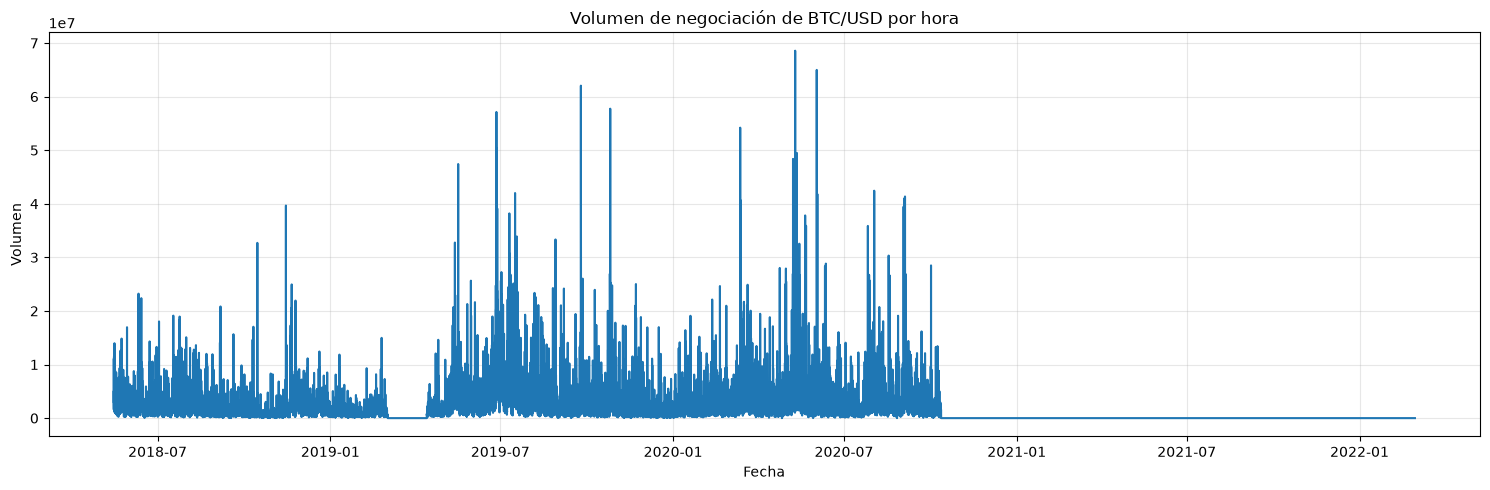

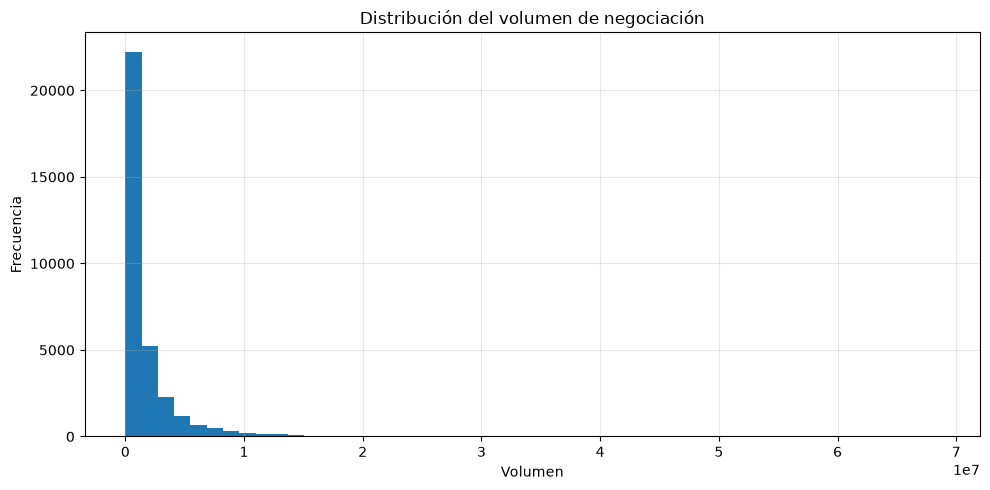

In [19]:
# ==========================================
# ANALISIS DEL VOLUMEN DE NEGOCIACION
# ==========================================

# Convertir volumen a formato numérico
df["volume"] = pd.to_numeric(df["volume"], errors="coerce")

print("Estadísticas del volumen:")
display(df["volume"].describe())

print("\nValores faltantes:", df["volume"].isna().sum())
print("Valores iguales a cero:", (df["volume"] == 0).sum())
print("Valores negativos:", (df["volume"] < 0).sum())

# Gráfico del volumen a lo largo del tiempo
plt.figure(figsize=(15, 5))
plt.plot(df[col_fecha], df["volume"])
plt.title("Volumen de negociación de BTC/USD por hora")
plt.xlabel("Fecha")
plt.ylabel("Volumen")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Distribución del volumen
plt.figure(figsize=(10, 5))
plt.hist(df["volume"].dropna(), bins=50)
plt.title("Distribución del volumen de negociación")
plt.xlabel("Volumen")
plt.ylabel("Frecuencia")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 15.1. Validación del volumen de negociación

El análisis del volumen permitió identificar una variación significativa en la escala de esta variable a lo largo del periodo estudiado. Entre 2018 y septiembre de 2020 se registran valores generalmente elevados, mientras que a partir de octubre de 2020 se observa una reducción pronunciada.

Por ejemplo, el volumen promedio semanal pasa de aproximadamente 1,97 millones durante la semana del 4 al 10 de octubre de 2020 a cerca de 204 mil durante la semana siguiente, y posteriormente se sitúa alrededor de unos cientos de unidades.

Este cambio ocurre mientras el precio de cierre continúa registrando valores del mismo orden de magnitud. Por lo tanto, la diferencia observada no puede atribuirse únicamente al comportamiento del precio.

La base contiene un único símbolo, BTC/USD, y no presenta valores negativos ni faltantes en la columna de volumen. Sin embargo, estos resultados no permiten determinar si el cambio responde a una modificación de unidades, de la fuente o del procesamiento de los datos.

En consecuencia, el volumen se documenta como una variable pendiente de validación. No se aplicarán correcciones arbitrarias ni se utilizará como indicador del agente hasta verificar su consistencia.

In [20]:
# ==========================================
# REVISION DEL VOLUMEN POR AÑO
# ==========================================

df["anio"] = df[col_fecha].dt.year

resumen_volumen = df.groupby("anio").agg(
    registros=("volume", "size"),
    volumen_promedio=("volume", "mean"),
    volumen_mediano=("volume", "median"),
    volumen_minimo=("volume", "min"),
    volumen_maximo=("volume", "max"),
    registros_cero=("volume", lambda x: (x == 0).sum()),
    registros_nulos=("volume", lambda x: x.isna().sum())
)

display(resumen_volumen.round(2))

print("Últimos 15 registros del dataset:")
display(df[[col_fecha, "close", "volume"]].tail(15))

print("Porcentaje de registros con volumen cero:")
print(round((df["volume"] == 0).mean() * 100, 2), "%")

print("Correlación entre precio de cierre y volumen:")
print(df[["close", "volume"]].corr().round(3))

,registros,volumen_promedio,volumen_mediano,volumen_minimo,volumen_maximo,registros_cero,registros_nulos
anio,,,,,,,
2018,5538,1962588.03,1258818.45,9323.62,39676868.06,0,0
2019,8760,2472967.77,1267277.83,16.80,62047295.99,0,0
2020,8784,2401207.67,1318830.04,0.00,68570613.16,4,0
2021,8760,205.82,122.95,0.01,6148.98,0,0
2022,1417,91.68,58.46,0.00,1276.45,1,0


Últimos 15 registros del dataset:


,date,close,volume
33244,2022-02-28 10:00:00+00:00,38404.20,80.171871
33245,2022-02-28 11:00:00+00:00,38367.53,78.152129
33246,2022-02-28 12:00:00+00:00,38271.13,110.749247
33247,2022-02-28 13:00:00+00:00,38056.20,120.015812
33248,2022-02-28 14:00:00+00:00,39840.10,292.856090
33249,2022-02-28 15:00:00+00:00,40846.38,365.055972
33250,2022-02-28 16:00:00+00:00,41008.37,291.623181
33251,2022-02-28 17:00:00+00:00,41432.91,192.789480
33252,2022-02-28 18:00:00+00:00,41233.87,71.233382
33253,2022-02-28 19:00:00+00:00,41362.52,114.268970


Porcentaje de registros con volumen cero:
0.02 %
Correlación entre precio de cierre y volumen:
        close  volume
close   1.000  -0.326
volume -0.326   1.000


In [21]:
# ==========================================
# INVESTIGAR EL CAMBIO DE ESCALA DEL VOLUMEN
# ==========================================

# Últimos registros de 2020 y primeros de 2021
columnas_revision = [col_fecha, "symbol", "close", "volume"]

display(
    df.loc[
        (df[col_fecha] >= "2020-12-28") &
        (df[col_fecha] < "2021-01-08"),
        columnas_revision
    ]
)

# Resumen mensual para identificar cuándo ocurre el cambio
df["mes"] = df[col_fecha].dt.to_period("M")

resumen_mensual = df.groupby("mes").agg(
    volumen_promedio=("volume", "mean"),
    volumen_mediano=("volume", "median"),
    precio_promedio=("close", "mean"),
    registros=("volume", "size")
)

display(resumen_mensual.round(2))

,date,symbol,close,volume
22986,2020-12-28 00:00:00+00:00,BTC/USD,26850.00,494.609730
22987,2020-12-28 01:00:00+00:00,BTC/USD,27048.50,401.370768
22988,2020-12-28 02:00:00+00:00,BTC/USD,27047.99,199.337613
22989,2020-12-28 03:00:00+00:00,BTC/USD,27250.92,287.943932
22990,2020-12-28 04:00:00+00:00,BTC/USD,26849.03,177.192287
...,...,...,...,...
23245,2021-01-07 19:00:00+00:00,BTC/USD,39100.00,1769.441893
23246,2021-01-07 20:00:00+00:00,BTC/USD,39148.66,833.975919
23247,2021-01-07 21:00:00+00:00,BTC/USD,39724.25,999.604395
23248,2021-01-07 22:00:00+00:00,BTC/USD,39719.25,539.126917


/var/folders/vb/87f3_yn55lgfpyx7cyq5xjmw0000gn/T/ipykernel_79512/3252632104.py:17: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["mes"] = df[col_fecha].dt.to_period("M")


,volumen_promedio,volumen_mediano,precio_promedio,registros
mes,,,,
2018-05,2798172.80,2077708.91,7851.45,402
2018-06,2265063.73,1577226.57,6784.71,720
2018-07,2362318.22,1536683.38,7098.46,744
2018-08,2146940.45,1511122.58,6689.26,744
2018-09,1479149.45,955354.62,6589.01,720
2018-10,1016286.35,643228.52,6415.20,744
2018-11,2247962.10,1189604.78,5388.03,720
2018-12,1772278.67,1310603.70,3671.08,744
2019-01,1018565.06,764563.21,3658.24,744


In [22]:
# ==========================================
# REVISION DEL CAMBIO DE ESCALA DEL VOLUMEN
# ==========================================

# Estadísticas semanales para ubicar el cambio
df["semana"] = df[col_fecha].dt.strftime("%Y-%U")

resumen_semanal = df.groupby("semana").agg(
    fecha_inicio=(col_fecha, "min"),
    fecha_fin=(col_fecha, "max"),
    volumen_promedio=("volume", "mean"),
    volumen_mediano=("volume", "median"),
    precio_promedio=("close", "mean"),
    registros=("volume", "size")
).reset_index(drop=True)

# Mostrar semanas entre septiembre y diciembre de 2020
display(
    resumen_semanal[
        (resumen_semanal["fecha_inicio"] >= "2020-09-01") &
        (resumen_semanal["fecha_inicio"] < "2021-01-01")
    ].round(2)
)

# Revisar si hay cambios en otras columnas
display(
    df.loc[
        (df[col_fecha] >= "2020-09-01") &
        (df[col_fecha] < "2021-01-01"),
        [col_fecha, "symbol", "open", "high", "low", "close", "volume"]
    ].iloc[::168].head(20)
)

/var/folders/vb/87f3_yn55lgfpyx7cyq5xjmw0000gn/T/ipykernel_79512/1181151601.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,fecha_inicio,fecha_fin,volumen_promedio,volumen_mediano,precio_promedio,registros
123,2020-09-06 00:00:00+00:00,2020-09-12 23:00:00+00:00,2932676.98,2167295.58,10244.49,168
124,2020-09-13 00:00:00+00:00,2020-09-19 23:00:00+00:00,2473320.14,1901567.62,10775.94,168
125,2020-09-20 00:00:00+00:00,2020-09-26 23:00:00+00:00,2473620.15,1644716.03,10615.88,168
126,2020-09-27 00:00:00+00:00,2020-10-03 23:00:00+00:00,2146514.82,1381044.98,10698.39,168
127,2020-10-04 00:00:00+00:00,2020-10-10 23:00:00+00:00,1972293.95,1330323.95,10813.28,168
128,2020-10-11 00:00:00+00:00,2020-10-17 23:00:00+00:00,204158.47,167.79,11398.77,168
129,2020-10-18 00:00:00+00:00,2020-10-24 23:00:00+00:00,294.97,150.48,12321.18,168
130,2020-10-25 00:00:00+00:00,2020-10-31 23:00:00+00:00,330.42,220.42,13350.05,168
131,2020-11-01 00:00:00+00:00,2020-11-07 23:00:00+00:00,420.16,271.82,14362.40,168
132,2020-11-08 00:00:00+00:00,2020-11-14 23:00:00+00:00,402.64,329.84,15685.02,168


,date,symbol,open,high,low,close,volume
20154,2020-09-01 00:00:00+00:00,BTC/USD,11655.00,11677.83,11515.00,11609.43,5.757071e+06
20322,2020-09-08 00:00:00+00:00,BTC/USD,10377.14,10446.18,10316.20,10322.90,9.970890e+06
20490,2020-09-15 00:00:00+00:00,BTC/USD,10675.15,10706.88,10652.09,10681.48,1.148911e+06
20658,2020-09-22 00:00:00+00:00,BTC/USD,10411.29,10489.59,10353.39,10453.88,2.275823e+06
20826,2020-09-29 00:00:00+00:00,BTC/USD,10689.48,10727.88,10655.82,10705.35,4.108477e+06
20994,2020-10-06 00:00:00+00:00,BTC/USD,10795.00,10801.86,10750.74,10762.20,4.629330e+05
21162,2020-10-13 00:00:00+00:00,BTC/USD,11539.42,11550.51,11421.51,11495.48,1.955346e+02
21330,2020-10-20 00:00:00+00:00,BTC/USD,11759.20,11759.72,11705.04,11726.91,7.827365e+01
21498,2020-10-27 00:00:00+00:00,BTC/USD,13065.10,13137.14,13057.09,13100.65,1.443782e+02
21666,2020-11-03 00:00:00+00:00,BTC/USD,13578.82,13589.00,13465.00,13537.10,4.976184e+02


In [23]:
# ==========================================
# VALIDACION FINAL DEL VOLUMEN
# ==========================================

print("Símbolos disponibles:")
display(df["symbol"].value_counts(dropna=False))

# Registros inmediatamente antes y después del cambio
fecha_inicio_revision = "2020-10-08"
fecha_fin_revision = "2020-10-15"

display(
    df.loc[
        (df[col_fecha] >= fecha_inicio_revision) &
        (df[col_fecha] < fecha_fin_revision),
        [col_fecha, "symbol", "open", "high", "low", "close", "volume"]
    ].to_string(index=False)
)

Símbolos disponibles:


symbol
BTC/USD    33259
Name: count, dtype: int64

'                     date  symbol     open     high      low    close       volume\n2020-10-08 00:00:00+00:00 BTC/USD 10669.14 10676.13 10642.31 10643.18 6.096762e+05\n2020-10-08 01:00:00+00:00 BTC/USD 10643.18 10656.37 10618.94 10644.73 9.107871e+05\n2020-10-08 02:00:00+00:00 BTC/USD 10644.73 10650.29 10626.94 10643.13 5.225745e+05\n2020-10-08 03:00:00+00:00 BTC/USD 10643.13 10661.39 10636.90 10644.54 8.651176e+05\n2020-10-08 04:00:00+00:00 BTC/USD 10644.54 10651.96 10632.59 10632.77 6.448279e+05\n2020-10-08 05:00:00+00:00 BTC/USD 10632.77 10641.36 10604.80 10614.97 1.795319e+06\n2020-10-08 06:00:00+00:00 BTC/USD 10614.97 10633.71 10606.47 10625.92 9.314060e+05\n2020-10-08 07:00:00+00:00 BTC/USD 10625.92 10625.92 10566.71 10590.89 3.594173e+06\n2020-10-08 08:00:00+00:00 BTC/USD 10590.89 10605.82 10555.55 10560.22 1.990912e+06\n2020-10-08 09:00:00+00:00 BTC/USD 10560.22 10579.39 10535.06 10565.02 2.330214e+06\n2020-10-08 10:00:00+00:00 BTC/USD 10565.02 10635.23 10557.82 10612.00 1.265

### 15.2. Causa del cambio de escala del volumen

El precio es casi igual antes y después de octubre de 2020, así que el cambio de escala no puede venir del mercado. Se prueba una hipótesis simple: si una columna está en BTC y la otra en dólares, entonces dólares ≈ BTC × precio de cierre. Se comprueba en qué filas se cumple esa relación con cada columna.

In [24]:
ratio_volume_en_usd = df["volume"] / (df["Volume USD"] * df["close"])
ratio_usd_en_usd = df["Volume USD"] / (df["volume"] * df["close"])

df["volume_esta_en"] = np.select(
    [np.isclose(ratio_volume_en_usd, 1, rtol=0.02), np.isclose(ratio_usd_en_usd, 1, rtol=0.02)],
    ["dólares (columnas intercambiadas)", "BTC (columnas correctas)"],
    default="no se puede decidir (volumen cero o redondeo)",
)
display(pd.crosstab(df[col_fecha].dt.to_period("Q").astype(str), df["volume_esta_en"]))

/var/folders/vb/87f3_yn55lgfpyx7cyq5xjmw0000gn/T/ipykernel_79512/975884381.py:9: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  display(pd.crosstab(df[col_fecha].dt.to_period("Q").astype(str), df["volume_esta_en"]))


volume_esta_en,BTC (columnas correctas),dólares (columnas intercambiadas),no se puede decidir (volumen cero o redondeo)
date,,,
2018Q2,0,1120,2
2018Q3,0,2208,0
2018Q4,0,2197,11
2019Q1,695,1464,1
2019Q2,305,1874,5
2019Q3,0,2201,7
2019Q4,0,2205,3
2020Q1,0,2164,20
2020Q2,0,2175,9


Desde el inicio de la serie hasta el 12 de octubre de 2020 la columna `volume` está en dólares y `Volume USD` está en BTC: las dos columnas vienen intercambiadas en la fuente. La única excepción es un tramo de unas 1.000 horas entre el 3 de marzo y el 13 de abril de 2019, que también explica el valor atípico de marzo de 2019 en la tabla mensual. Desde el 12 de octubre de 2020 las columnas están en el orden correcto. Ese es el "cambio de escala" de la sección 15.1: no es un cambio del mercado, es un cambio en cómo la fuente guardó las columnas.

Aunque la causa ya está identificada, el volumen se mantiene fuera del estado del agente. Corregirlo exigiría reconstruir la columna con una regla propia, y su relación con las decisiones de inversión no se analizó en este proyecto. Queda como mejora futura.

### 15.2. Tratamiento de valores faltantes

Los indicadores técnicos y financieros se calculan a partir de observaciones anteriores. Por esta razón, las primeras filas pueden presentar valores faltantes cuando no existe suficiente información histórica para calcular los retornos o las ventanas móviles.

Estos valores deben distinguirse de los faltantes inesperados. En lugar de reemplazarlos automáticamente por cero, se revisará cuáles corresponden al comportamiento esperado de las fórmulas y se determinará el periodo mínimo de observaciones necesario para construir la base analítica final.

La base definitiva conservará únicamente las filas que dispongan de los valores requeridos para las variables seleccionadas, evitando introducir información artificial en los indicadores.

In [25]:
# ==========================================
# REVISION DE VALORES FALTANTES
# ==========================================

columnas_indicadores = [
    "return",
    "log_return",
    "return_24h",
    "sma_24h",
    "price_vs_sma_24h",
    "volatility_24h",
    "volatility_168h"
]

resumen_nulos = pd.DataFrame({
    "valores_nulos": df[columnas_indicadores].isna().sum(),
    "porcentaje_nulos": (
        df[columnas_indicadores].isna().mean() * 100
    ).round(3)
})

display(resumen_nulos)

print("Dimensiones originales:", df.shape)

print(
    "Primer registro con volatilidad de 168 horas:",
    df.loc[df["volatility_168h"].notna(), col_fecha].min()
)

,valores_nulos,porcentaje_nulos
return,1,0.003
log_return,1,0.003
return_24h,24,0.072
sma_24h,23,0.069
price_vs_sma_24h,23,0.069
volatility_24h,24,0.072
volatility_168h,168,0.505


Dimensiones originales: (33259, 23)
Primer registro con volatilidad de 168 horas: 2018-05-22 06:00:00+00:00


### 15.3. Validación de la estructura temporal

La base presenta una frecuencia horaria y las observaciones se encuentran ordenadas cronológicamente. La validación realizada identificó intervalos consecutivos de una hora y ausencia de fechas duplicadas.

Esta estructura es relevante para el proyecto, ya que las observaciones deben utilizarse respetando su orden temporal. De esta manera, se evita mezclar información futura con información pasada durante la preparación y evaluación del modelo.

Antes de construir la base definitiva, se verificará nuevamente la continuidad temporal después del tratamiento de los valores faltantes.

### 15.6. Conclusiones de la validación final

La revisión de los valores faltantes permitió identificar que estos se concentran principalmente en las primeras observaciones de los indicadores calculados a partir de ventanas temporales.

Las variables `return` y `log_return` presentan un valor faltante cada una, correspondiente a la primera observación, ya que requieren un precio anterior para calcular la variación. Por su parte, `return_24h` y `volatility_24h` presentan 24 valores faltantes, mientras que `sma_24h` y `price_vs_sma_24h` presentan 23. Estos valores se relacionan con la necesidad de disponer de suficiente información histórica para realizar los cálculos.

La variable `volatility_168h` presenta 168 valores faltantes, equivalentes aproximadamente al 0,505 % del conjunto de datos. Su primer valor disponible corresponde al 22 de mayo de 2018 a las 06:00 UTC, después de completar la ventana histórica de 168 horas.

En consecuencia, los valores faltantes iniciales se consideran esperados por la construcción de los indicadores. Para preparar la base analítica se conservarán las observaciones que dispongan de los valores requeridos para las variables seleccionadas, sin sustituir los valores faltantes por ceros ni introducir información artificial.

Adicionalmente, se identificó que el cambio de escala del volumen en octubre de 2020 se debe a que la fuente trae intercambiadas las columnas `volume` y `Volume USD` antes de esa fecha (sección 15.2). El volumen no se usa en el estado del agente.

Finalmente, la preparación de la base continuará con la selección de variables, la separación cronológica de los datos y la exportación del archivo analítico definitivo.

### 15.7. Selección de variables para la base analítica

A partir de los resultados del análisis exploratorio, se seleccionan las variables que describen el comportamiento del precio y algunas características derivadas de su evolución temporal.

Se conservarán los precios de apertura, máximo, mínimo y cierre, junto con los indicadores `return_24h`, `price_vs_sma_24h` y `volatility_24h`. La fecha se mantendrá para garantizar el orden cronológico y facilitar la trazabilidad de las observaciones.

El volumen de negociación no se incluirá inicialmente entre las variables candidatas debido a la diferencia de escala identificada durante el periodo analizado. Asimismo, `volatility_168h` se excluirá de esta primera selección para simplificar el tratamiento de los valores faltantes.

Esta selección es preliminar y deberá revisarse al definir las variables de observación que utilizará el agente.

In [26]:
# ==========================================
# 15.7. SELECCION DE VARIABLES
# ==========================================

columnas_finales = [
    col_fecha,
    "open",
    "high",
    "low",
    "close",
    "return_24h",
    "price_vs_sma_24h",
    "volatility_24h"
]

df_final = df[columnas_finales].copy()

# Eliminar únicamente filas que no tengan
# información en los indicadores seleccionados
df_final = (
    df_final
    .dropna(
        subset=[
            "return_24h",
            "price_vs_sma_24h",
            "volatility_24h"
        ]
    )
    .sort_values(col_fecha)
    .reset_index(drop=True)
)

print("Dimensiones de la base analítica:", df_final.shape)

print("\nValores faltantes:")
display(df_final.isna().sum())

print("\nPrimeras observaciones:")
display(df_final.head())

print("\nÚltimas observaciones:")
display(df_final.tail())

Dimensiones de la base analítica: (33235, 8)

Valores faltantes:


date                0
open                0
high                0
low                 0
close               0
return_24h          0
price_vs_sma_24h    0
volatility_24h      0
dtype: int64


Primeras observaciones:


,date,open,high,low,close,return_24h,price_vs_sma_24h,volatility_24h
0,2018-05-16 06:00:00+00:00,8220.40,8267.12,8176.91,8238.80,-0.057452,-0.031495,0.008531
1,2018-05-16 07:00:00+00:00,8238.80,8255.00,8213.79,8232.99,-0.057903,-0.029773,0.008526
2,2018-05-16 08:00:00+00:00,8232.99,8261.24,8200.00,8207.48,-0.059691,-0.030298,0.008523
3,2018-05-16 09:00:00+00:00,8207.48,8263.93,8207.48,8243.45,-0.053382,-0.023815,0.008639
4,2018-05-16 10:00:00+00:00,8243.45,8455.66,8237.10,8371.13,-0.048292,-0.006613,0.009037



Últimas observaciones:


,date,open,high,low,close,return_24h,price_vs_sma_24h,volatility_24h
33230,2022-02-28 20:00:00+00:00,41361.99,41971.00,41284.11,41914.97,0.103611,0.077791,0.012384
33231,2022-02-28 21:00:00+00:00,41917.09,41917.09,41542.60,41659.53,0.113593,0.066367,0.011909
33232,2022-02-28 22:00:00+00:00,41657.23,44256.08,41650.29,42907.32,0.134131,0.092395,0.012932
33233,2022-02-28 23:00:00+00:00,43085.30,43364.81,42892.37,43178.98,0.144946,0.092973,0.012805
33234,2022-03-01 00:00:00+00:00,43221.71,43626.49,43185.48,43312.27,0.152806,0.089749,0.012660


### 15.8. Separación cronológica de entrenamiento y prueba

Con el propósito de evaluar el agente sobre observaciones que no hayan sido utilizadas durante el entrenamiento, la base analítica se dividirá cronológicamente en dos subconjuntos.

Se utilizará el 70 % inicial de las observaciones para entrenamiento y el 30 % final para prueba. La división conservará el orden temporal de los registros, sin mezclar aleatoriamente las observaciones.

El conjunto de prueba representará un periodo posterior al de entrenamiento, lo que permitirá analizar el desempeño del agente ante condiciones de mercado diferentes de las observadas durante su aprendizaje. Las fechas y dimensiones de ambos subconjuntos se registrarán para garantizar la trazabilidad del proceso.

In [27]:
# ==========================================
# 15.8. SEPARACION CRONOLOGICA 70/30
# ==========================================

# Garantizar orden cronológico
df_final = df_final.sort_values(col_fecha).reset_index(drop=True)

# Punto de corte: 70 % para entrenamiento
punto_corte = int(len(df_final) * 0.70)

df_train = df_final.iloc[:punto_corte].copy()
df_test = df_final.iloc[punto_corte:].copy()

# Resumen de la división
print("Total de observaciones:", len(df_final))
print("Observaciones de entrenamiento:", len(df_train))
print("Observaciones de prueba:", len(df_test))

print("\nPorcentaje de entrenamiento:",
      round(len(df_train) / len(df_final) * 100, 2), "%")
print("Porcentaje de prueba:",
      round(len(df_test) / len(df_final) * 100, 2), "%")

print("\nPeriodo de entrenamiento:")
print(df_train[col_fecha].min(), "hasta", df_train[col_fecha].max())

print("\nPeriodo de prueba:")
print(df_test[col_fecha].min(), "hasta", df_test[col_fecha].max())

# Verificaciones
print("\n¿Entrenamiento ordenado?",
      df_train[col_fecha].is_monotonic_increasing)
print("¿Prueba ordenada?",
      df_test[col_fecha].is_monotonic_increasing)
print("¿Los periodos están separados?",
      df_train[col_fecha].max() < df_test[col_fecha].min())

Total de observaciones: 33235
Observaciones de entrenamiento: 23264
Observaciones de prueba: 9971

Porcentaje de entrenamiento: 70.0 %
Porcentaje de prueba: 30.0 %

Periodo de entrenamiento:
2018-05-16 06:00:00+00:00 hasta 2021-01-09 13:00:00+00:00

Periodo de prueba:
2021-01-09 14:00:00+00:00 hasta 2022-03-01 00:00:00+00:00

¿Entrenamiento ordenado? True
¿Prueba ordenada? True
¿Los periodos están separados? True


La división cronológica generó dos subconjuntos a partir de las 33.235 observaciones de la base analítica. El conjunto de entrenamiento contiene 23.264 registros, equivalentes al 70 % de los datos, mientras que el conjunto de prueba contiene 9.971 registros, correspondientes al 30 % restante.

El periodo de entrenamiento comprende desde el 16 de mayo de 2018 a las 06:00 UTC hasta el 9 de enero de 2021 a las 13:00 UTC. Por su parte, el periodo de prueba comienza el 9 de enero de 2021 a las 14:00 UTC y finaliza el 1 de marzo de 2022 a las 00:00 UTC.

Las verificaciones confirmaron que ambos subconjuntos conservan el orden cronológico y que no existe superposición entre sus periodos. Esta separación permitirá evaluar posteriormente el agente sobre datos posteriores a los utilizados para su entrenamiento.

### 15.5. Exportación de la base analítica final

Una vez finalizadas las validaciones y la selección de variables, se exportará la base analítica en formato CSV. El archivo incluirá las fechas, los precios y los indicadores seleccionados para el proyecto.

Se comprobará que el archivo exportado pueda cargarse nuevamente, que las columnas requeridas estén disponibles y que no existan valores faltantes en las variables utilizadas por el modelo. También se conservará la referencia a la fuente original y el registro de las transformaciones aplicadas.

In [28]:
# ==========================================
# 15.9. EXPORTACION Y VALIDACION
# ==========================================

# Carpeta de salida dentro del repositorio
carpeta_salida = RAIZ / "data" / "procesados"
carpeta_salida.mkdir(parents=True, exist_ok=True)

archivo_completo = carpeta_salida / "base_analitica.csv"
archivo_train = carpeta_salida / "entrenamiento.csv"
archivo_test = carpeta_salida / "prueba.csv"

df_final.to_csv(archivo_completo, index=False)
df_train.to_csv(archivo_train, index=False)
df_test.to_csv(archivo_test, index=False)

base_verificada = pd.read_csv(archivo_completo)
train_verificado = pd.read_csv(archivo_train)
test_verificado = pd.read_csv(archivo_test)

print("BASE ANALITICA")
print("Filas:", len(base_verificada))
print("Columnas:", len(base_verificada.columns))
print("Valores faltantes:", base_verificada.isna().sum().sum())
print("\nENTRENAMIENTO")
print("Filas:", len(train_verificado))
print("\nPRUEBA")
print("Filas:", len(test_verificado))
print("\n¿Coinciden las dimensiones?",
      len(train_verificado) + len(test_verificado) == len(base_verificada))

# El código del proyecto (src/data.py) debe producir exactamente lo mismo
from src.data import cargar_conjuntos
conjuntos = cargar_conjuntos()
assert conjuntos["entrenamiento"].drop(columns="date").equals(df_train.reset_index(drop=True).drop(columns=col_fecha))
assert conjuntos["prueba"].drop(columns="date").equals(df_test.reset_index(drop=True).drop(columns=col_fecha))
print("\nsrc/data.py reproduce exactamente esta división.")

BASE ANALITICA
Filas: 33235
Columnas: 8
Valores faltantes: 0

ENTRENAMIENTO
Filas: 23264

PRUEBA
Filas: 9971

¿Coinciden las dimensiones? True

src/data.py reproduce exactamente esta división.


### 15.10. Periodo de validación dentro del entrenamiento

El 20 % final del entrenamiento se separa como validación. Sirve para comparar versiones del agente y elegir una sin mirar la prueba. El 80 % inicial (periodo de ajuste) es el único con el que el agente aprende.

In [29]:
for nombre, tabla in conjuntos.items():
    print(f"{nombre:>13}: {len(tabla):>6,} filas | {tabla.date.min()} -> {tabla.date.max()} | "
          f"precio {tabla.close.iloc[0]:,.0f} -> {tabla.close.iloc[-1]:,.0f}")

entrenamiento: 23,264 filas | 2018-05-16 06:00:00+00:00 -> 2021-01-09 13:00:00+00:00 | precio 8,239 -> 41,133
       ajuste: 18,611 filas | 2018-05-16 06:00:00+00:00 -> 2020-06-29 16:00:00+00:00 | precio 8,239 -> 9,115
   validacion:  4,653 filas | 2020-06-29 17:00:00+00:00 -> 2021-01-09 13:00:00+00:00 | precio 9,154 -> 41,133
       prueba:  9,971 filas | 2021-01-09 14:00:00+00:00 -> 2022-03-01 00:00:00+00:00 | precio 40,874 -> 43,312


Los tres periodos son muy distintos. En el **ajuste** (mayo de 2018 a junio de 2020) el precio termina casi donde empezó, con caídas de hasta −70 % en el camino. La **validación** (julio de 2020 a enero de 2021) es una subida casi continua: el precio se multiplica por 4,5. La **prueba** (enero de 2021 a marzo de 2022) sube hasta 68.000 USD y luego cae: termina apenas un 6 % arriba. Esta diferencia entre periodos es una de las limitaciones centrales del proyecto.

### 15.11. Auditoría de información futura

Para cada una de 300 horas elegidas al azar se recalculan los indicadores usando solo las filas hasta esa hora. Si el valor cambiara, el indicador estaría usando el futuro.

In [30]:
from src.data import auditar_lookahead
revisadas = auditar_lookahead(pd.read_csv(RUTA_CSV))
print(f"{revisadas} horas revisadas: ningún indicador usa información posterior a la hora t.")

300 horas revisadas: ningún indicador usa información posterior a la hora t.


### 15.12. ¿Qué anticipa el estado?

Esta revisión se hace **solo con el periodo de ajuste**, para no usar la validación ni la prueba al diseñar el agente. Se mide la correlación de cada indicador de la hora t con el retorno y con el tamaño del movimiento de la hora siguiente.

In [31]:
aj = conjuntos["ajuste"].copy()
r_sig = np.log(aj["close"]).diff().shift(-1)
filas = []
for col in ["return_24h", "price_vs_sma_24h", "volatility_24h"]:
    filas.append({"indicador": col,
                  "corr. con el retorno siguiente": aj[col].corr(r_sig),
                  "corr. con |retorno siguiente|": aj[col].corr(r_sig.abs())})
display(pd.DataFrame(filas).round(3))
r_aj = np.log(aj["close"]).diff().dropna()
print(f"Retorno medio por hora en el ajuste: {r_aj.mean():.2e} | desviación: {r_aj.std():.2e} "
      f"| relación media/desviación: {r_aj.mean() / r_aj.std():.4f}")

,indicador,corr. con el retorno siguiente,corr. con |retorno siguiente|
0,return_24h,-0.006,-0.080
1,price_vs_sma_24h,-0.006,-0.089
2,volatility_24h,-0.003,0.366


Retorno medio por hora en el ajuste: 5.43e-06 | desviación: 8.07e-03 | relación media/desviación: 0.0007


Ningún indicador anticipa la **dirección** de la hora siguiente (correlaciones cercanas a cero). En cambio, la volatilidad reciente sí anticipa el **tamaño** del siguiente movimiento: la volatilidad se agrupa, como se vio en la sección 8. Además, en el periodo de ajuste el retorno medio por hora es más de mil veces más pequeño que su desviación estándar. Estas dos observaciones explican buena parte del comportamiento del agente y orientan el diseño de la recompensa (ver informe, sección de recompensas).

### Conclusiones del análisis exploratorio

El análisis exploratorio permitió identificar las principales características de la serie histórica del par BTC/USD, incluyendo su evolución temporal, la variabilidad de los retornos y los cambios en la volatilidad del mercado. Asimismo, se validó la continuidad de los registros horarios y se revisó la calidad de las variables disponibles.

A partir de este análisis, se seleccionaron variables relacionadas con los precios de mercado, los retornos recientes, la diferencia entre el precio de cierre y su media móvil, y la volatilidad de corto plazo. Estas variables proporcionan información complementaria sobre el comportamiento reciente del activo y podrán utilizarse como componentes del estado del agente de aprendizaje por refuerzo.

El volumen de negociación se analizó como parte de la exploración. Su cambio de escala en octubre de 2020 se debe a columnas intercambiadas en la fuente; aun así no se incluyó en el estado del agente.

Finalmente, los datos se organizaron cronológicamente y se separaron en ajuste, validación y prueba, sin mezclar periodos y sin usar información futura en los indicadores. Los tres periodos tienen tendencias muy distintas, lo que anticipa la principal dificultad del proyecto: un mercado que no se comporta igual en el tiempo.